## 1. Load and preprocess the Cats vs Dogs dataset

Before running the code below, please make sure you have the 'Cats vs Dogs' dataset downloaded and organized in a directory structure like this:

```
dataset/
├── train/
│   ├── cats/
│   │   ├── cat.0.jpg
│   │   ├── ...
│   └── dogs/
│       ├── dog.0.jpg
│       └── ...
└── val/
    ├── cats/
    │   ├── cat.2000.jpg
    │   ├── ...
    └── dogs/
        ├── dog.2000.jpg
        └── ...
```

You can typically download this dataset from platforms like Kaggle (e.g., 'Dogs vs. Cats' competition dataset). Upload the `dataset` folder to your Colab environment or Google Drive and adjust the `data_dir` path accordingly.

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import os
import shutil
import glob

# Define data directories (adjust this path if your dataset is in a different location)
data_dir = './dataset'
train_dir = os.path.join(data_dir, 'train')
val_dir = os.path.join(data_dir, 'val') # Or 'test' depending on your dataset split

# Helper function to unpack a zip file if found
def unpack_dataset_if_zipped(current_data_dir, current_train_dir, current_val_dir, zip_name_pattern='*.zip'):
    new_data_dir, new_train_dir, new_val_dir = current_data_dir, current_train_dir, current_val_dir

    if not os.path.exists(new_data_dir) or not os.listdir(new_data_dir):
        print(f"'{new_data_dir}' not found or empty. Checking for zip files...")
        zip_files = glob.glob(zip_name_pattern)
        if zip_files:
            print(f"Found zip files: {zip_files}. Attempting to unpack into '{new_data_dir}'...")
            os.makedirs(new_data_dir, exist_ok=True)
            for zip_file in zip_files:
                try:
                    shutil.unpack_archive(zip_file, new_data_dir)
                    print(f"Successfully unpacked {zip_file} into {new_data_dir}")
                except Exception as e:
                    print(f"Error unpacking {zip_file}: {e}")

            # After unpacking, we need to check if train/val directories are directly inside data_dir
            # or if there's an intermediate folder (e.g., 'dogs-vs-cats')
            temp_train_dir = os.path.join(new_data_dir, 'train')
            temp_val_dir = os.path.join(new_data_dir, 'val')

            if not os.path.exists(temp_train_dir) and not os.path.exists(temp_val_dir):
                subdirs = [d for d in os.listdir(new_data_dir) if os.path.isdir(os.path.join(new_data_dir, d))]
                if len(subdirs) == 1:
                    print(f"Found single subdirectory '{subdirs[0]}' in '{new_data_dir}'. Adjusting paths...")
                    new_data_dir = os.path.join(new_data_dir, subdirs[0])
                    new_train_dir = os.path.join(new_data_dir, 'train')
                    new_val_dir = os.path.join(new_data_dir, 'val') # Or 'test'
                else:
                    print("Could not automatically find 'train' and 'val' directories after unpacking.")
                    print("Please manually verify the dataset structure inside 'dataset/'.")
        else:
            print(f"No zip files found matching '{zip_name_pattern}'.")
            print("Please upload your dataset to the Colab environment or Google Drive and adjust 'data_dir'.")

    return new_data_dir, new_train_dir, new_val_dir

# Call the helper function to try and unpack if needed, and update the global paths
data_dir, train_dir, val_dir = unpack_dataset_if_zipped(data_dir, train_dir, val_dir)

# Define transformations for the images
# ResNet models typically expect 224x224 input images
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]) # ImageNet normalization
])

transform_val = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Check if the directories exist before loading datasets
if not os.path.exists(train_dir):
    raise FileNotFoundError(f"Training directory not found: {train_dir}. Please ensure your dataset is correctly organized.")
if not os.path.exists(val_dir):
    # Often, Kaggle 'dogs-vs-cats' comes with train and test. We can use 'test' as 'val'
    alternative_val_dir = os.path.join(data_dir, 'test')
    if os.path.exists(alternative_val_dir):
        print(f"Validation directory '{val_dir}' not found, using '{alternative_val_dir}' as validation.")
        val_dir = alternative_val_dir
    else:
        raise FileNotFoundError(f"Validation directory not found: {val_dir} or {alternative_val_dir}. Please ensure your dataset is correctly organized.")

# Load the datasets
train_dataset = ImageFolder(train_dir, transform=transform_train)
val_dataset = ImageFolder(val_dir, transform=transform_val)

# Define data loaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# Get class names
classes = train_dataset.classes
print(f"Classes: {classes}")
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")

'./dataset' not found or empty. Checking for zip files...
No zip files found matching '*.zip'.
Please upload your dataset to the Colab environment or Google Drive and adjust 'data_dir'.


FileNotFoundError: Training directory not found: ./dataset/train. Please ensure your dataset is correctly organized.

In [ ]:
# Function to show an image (denormalized for display)
def imshow(img):
    img = img / 2 + 0.5  # Denormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# Get some random training images
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Show images
# Limit to 4 images for clear display
imshow(torchvision.utils.make_grid(images[:4]))
# Print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

NameError: name 'train_loader' is not defined

## 2. Implement the required PyTorch model (ResNet18)

In [ ]:
import torch.nn as nn
import torchvision.models as models

# Load a pre-trained ResNet18 model
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Freeze all parameters in the network (optional, but good for fine-tuning)
# for param in model.parameters():
#     param.requires_grad = False

# Modify the final fully connected layer for our specific classification task
# ResNet18's last layer is 'fc'
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, len(classes)) # Output should be 2 for Cats vs Dogs

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Model architecture:")
print(model)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 108MB/s]


NameError: name 'classes' is not defined

## 3. Train using suitable hyperparameters

In [ ]:
import torch.optim as optim

# Define Loss function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001) # Using Adam optimizer

# Number of training epochs
num_epochs = 10 # You can increase this for better performance and convergence

print("Starting model training...")

train_losses = []

for epoch in range(num_epochs):
    model.train() # Set model to training mode
    running_loss = 0.0
    for i, (inputs, labels) in enumerate(train_loader, 0):
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Print statistics
        running_loss += loss.item()
        if i % 100 == 99:    # Print every 100 mini-batches
            print(f'Epoch [{epoch + 1}/{num_epochs}], Batch [{i + 1}/{len(train_loader)}] Loss: {running_loss / 100:.3f}')
            train_losses.append(running_loss / 100)
            running_loss = 0.0

print('Finished Training')


Starting model training...


NameError: name 'train_loader' is not defined

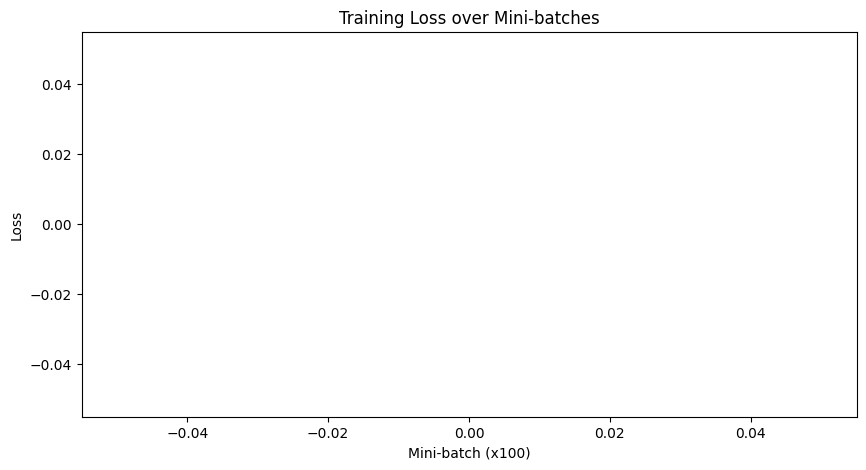

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses)
plt.title('Training Loss over Mini-batches')
plt.xlabel('Mini-batch (x100)')
plt.ylabel('Loss')
plt.show()

## 4. Evaluate using appropriate metrics

In [ ]:
correct = 0
total = 0

# Set the model to evaluation mode
model.eval()

# We don't need to calculate gradients for validation
with torch.no_grad():
    for data in val_loader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)

        # Calculate outputs by running images through the network
        outputs = model(images)

        # The class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the {total} validation images: {100 * correct / total:.2f} %')

# Prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# Again, no gradients needed
with torch.no_grad():
    for data in val_loader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predictions = torch.max(outputs, 1)
        # Collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# Print accuracy for each class
print('\nAccuracy for each class:')
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname] if total_pred[classname] > 0 else 0
    print(f'Accuracy for class {classname:5s} is {accuracy:.1f} %')


NameError: name 'val_loader' is not defined

## 5. Visualize results (predictions)

In [ ]:
# Get some random validation images
dataiter = iter(val_loader)
images, labels = next(dataiter)

# Move images to the device
images = images.to(device)

# Print images
imshow(torchvision.utils.make_grid(images[:4].cpu())) # Move back to CPU for imshow
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

# Make predictions
model.eval() # Set model to evaluation mode
with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

print('Predicted:   ', ' '.join(f'{classes[predicted[j]]:5s}' for j in range(4)))

NameError: name 'val_loader' is not defined

## 6. Summarize observations and conclusions

In [ ]:
# This cell is left empty for the user to fill in their observations and conclusions after reviewing the results.
# Example points to consider:
# - What was the overall accuracy?
# - How did the training loss behave (decreasing, fluctuating)?
# - Were there any classes that performed particularly well or poorly?
# - What potential improvements could be made (e.g., more epochs, data augmentation, different model, hyperparameter tuning)?

print("Please provide your observations and conclusions based on the training loss plot, overall accuracy, and class-wise accuracy.")


Please provide your observations and conclusions based on the training loss plot, overall accuracy, and class-wise accuracy.


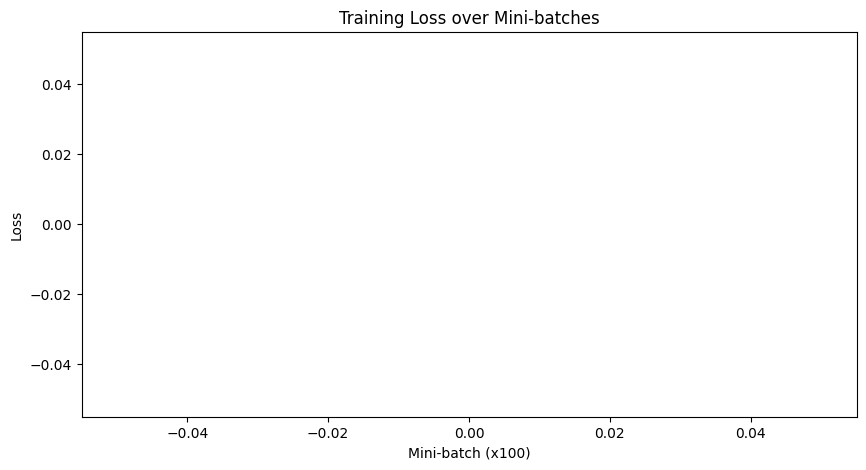

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses)
plt.title('Training Loss over Mini-batches')
plt.xlabel('Mini-batch (x100)')
plt.ylabel('Loss')
plt.show()

## 4. Evaluate using appropriate metrics

In [ ]:
correct = 0
total = 0

# Set the model to evaluation mode
model.eval()

# We don't need to calculate gradients for validation
with torch.no_grad():
    for data in val_loader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)

        # Calculate outputs by running images through the network
        outputs = model(images)

        # The class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the {total} validation images: {100 * correct / total:.2f} %')

# Prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# Again, no gradients needed
with torch.no_grad():
    for data in val_loader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predictions = torch.max(outputs, 1)
        # Collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# Print accuracy for each class
print('\nAccuracy for each class:')
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname] if total_pred[classname] > 0 else 0
    print(f'Accuracy for class {classname:5s} is {accuracy:.1f} %')


NameError: name 'val_loader' is not defined

## 5. Visualize results (predictions)

In [ ]:
# Get some random validation images
dataiter = iter(val_loader)
images, labels = next(dataiter)

# Move images to the device
images = images.to(device)

# Print images
imshow(torchvision.utils.make_grid(images[:4].cpu())) # Move back to CPU for imshow
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

# Make predictions
model.eval() # Set model to evaluation mode
with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

print('Predicted:   ', ' '.join(f'{classes[predicted[j]]:5s}' for j in range(4)))

NameError: name 'val_loader' is not defined

## 6. Summarize observations and conclusions

In [ ]:
# This cell is left empty for the user to fill in their observations and conclusions after reviewing the results.
# Example points to consider:
# - What was the overall accuracy?
# - How did the training loss behave (decreasing, fluctuating)?
# - Were there any classes that performed particularly well or poorly?
# - What potential improvements could be made (e.g., more epochs, data augmentation, different model, hyperparameter tuning)?

print("Please provide your observations and conclusions based on the training loss plot, overall accuracy, and class-wise accuracy.")


Please provide your observations and conclusions based on the training loss plot, overall accuracy, and class-wise accuracy.
